# Dans ce notebook on va comparer la trajectoire de Strava et notre Trajectoire

In [114]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
import os

# Ajoute le dossier parent au chemin Python
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from utils.correction_erreur_systematique import transformation_csv_dataframe
rayon_terre = 6371000 #rayon de la terre en m

### Lecture et exploration des données 
Dans cette partie on recupère les deux CSV correspondant qu'on explore et plote

In [115]:
own_data_brut= transformation_csv_dataframe("/home/barry/pi_itineraire/IMU_GPS/data/acq_v2_26_250_26.csv")
own_data_kalman = transformation_csv_dataframe("/home/barry/pi_itineraire/IMU_GPS/data/acq_v_kalman_2_26_250_26.csv")
data_strava = transformation_csv_dataframe("/home/barry/pi_itineraire/Strava/course_a_pied_le_soir.csv")

In [116]:
print(own_data_brut.head())
print(data_strava.head())

      Timestamp                    UTC   Latitude  Longitude  Altitude  \
0  1.779389e+09  2000/01/01 - 18:35:19  49.385517   1.071347      76.4   
1  1.779389e+09  2000/01/01 - 18:35:19  49.385517   1.071347      76.4   
2  1.779389e+09  2000/01/01 - 18:35:20  49.385517   1.071347      76.4   
3  1.779389e+09  2000/01/01 - 18:35:20  49.385517   1.071347      76.4   
4  1.779389e+09  2000/01/01 - 18:35:20  49.385517   1.071347      76.4   

   Nb Satellites  GPS Valid  Fix Quality  Fix Type  HDOP  ...  COG   Accel X  \
0             17          1            1         1   0.7  ...  0.0  0.965752   
1             17          1            1         1   0.7  ...  0.0  0.941657   
2             17          1            1         3   0.7  ...  0.0  1.050542   
3             17          1            1         3   0.7  ...  0.0  1.046577   
4             17          1            1         3   0.7  ...  0.0  0.933605   

    Accel Y   Accel Z    Gyro X    Gyro Y   Gyro Z  Magneto X  Magneto Y  

In [117]:
# Filtre les lignes GPS invalides AVANT de sélectionner les colonnes
# GPS Valid == 1 + Fix Quality >= 1 : position GPS confirmée
own_data2 = own_data_brut[
    (own_data_brut['GPS Valid'] == 1) & (own_data_brut['Fix Quality'] >= 1)
][['Latitude', 'Longitude', 'UTC']].copy()

# Le fichier Kalman n'a pas de colonne GPS Valid → filtre sur les bornes géographiques
# (lat/lon hors [-90,90]/[-180,180] = divergence Kalman certaine)
own_data3 = own_data_kalman[
    (own_data_kalman['Latitude'].between(-90, 90)) &
    (own_data_kalman['Longitude'].between(-180, 180))
][['Latitude', 'Longitude', 'UTC']].copy()

nb_ligne_onw_brut, _   = own_data2.shape
nb_ligne_own_kalman, _ = own_data3.shape
nb_ligne_strava, _     = data_strava.shape
print('Nombre de lignes données brutes  :', nb_ligne_onw_brut)
print('Nombre de lignes données Kalman  :', nb_ligne_own_kalman)
print('Nombre de lignes Strava          :', nb_ligne_strava)


Nombre de lignes données brutes  : 3822
Nombre de lignes données Kalman  : 4481
Nombre de lignes Strava          : 2391


## Synchronisation des deux pour avoir le même time selon Strava
On transforme l'UTC qui est en string en datetime pour pouvoir faire un comparaison pour la synchronisation

In [118]:
own_data2['UTC'] = pd.to_datetime(own_data2['UTC'], format='%Y/%m/%d - %H:%M:%S', errors='coerce').copy()
own_data2 = own_data2.dropna()
own_data3['UTC'] = pd.to_datetime(own_data3['UTC'],format='%Y/%m/%d - %H:%M:%S', errors='coerce').copy()
own_data3=own_data3.dropna()
data_strava['UTC'] = pd.to_datetime(data_strava['UTC'],format='%Y/%m/%d - %H:%M:%S', errors='coerce').copy()
data_strava=data_strava.dropna()


print(own_data2.describe())
print(own_data3.describe())
print(data_strava.describe())

          Latitude    Longitude                            UTC
count  3769.000000  3769.000000                           3769
mean     48.681375     1.297179  2026-05-01 07:53:09.154683136
min       0.810167     1.071291            2000-01-01 18:35:19
25%      49.385044     1.077324            2026-05-21 18:41:59
50%      49.386231     1.080129            2026-05-21 18:48:46
75%      49.387692     1.082270            2026-05-21 18:55:26
max      49.396667    49.389735            2026-05-21 19:02:01
std       5.643824     3.237590                            NaN
          Latitude    Longitude                            UTC
count  4251.000000  4251.000000                           4251
mean     48.450718     1.274304  2026-05-03 15:32:49.633968640
min     -85.453699   -73.476498            2000-01-01 18:35:19
25%      49.384837     1.076078            2026-05-21 18:41:49
50%      49.385898     1.079723            2026-05-21 18:48:46
75%      49.387914     1.082342            2026-05-21 1

#### Fonction de synchronisation des données à une fréquence de 1(Hz)
On prend pour le brut et le kalman le prémière acuqistion de chaque séconde 

In [119]:
def sync(df1, df2, df3, col_time='UTC'):
    """
    Merge trois DataFrames en synchronisant sur l'intersection commune,
    à la seconde près (1 Hz). Agrège les doublons par moyenne.
    """
    dfs = [df1.copy(), df2.copy(), df3.copy()]
    result = []

    for df in dfs:
        df[col_time] = pd.to_datetime(df[col_time])
        df[col_time] = df[col_time].dt.floor('s')
        
        # Moyenner les acquisitions par seconde (gère le 26 Hz)
        numeric_cols = df.select_dtypes(include='number').columns
        df = df.groupby(col_time)[numeric_cols].mean()
        result.append(df)

    # Intersection des trois index
    common = result[0].index
    for df in result[1:]:
        common = common.intersection(df.index)

    print(f"Points communs (3 df): {len(common)}")
    print(f"Plage temporelle: {common.min()} → {common.max()}")

    return tuple(df.loc[common].reset_index() for df in result)

In [120]:
own_data_brut_sync,own_data_kalman_sync , data_strava_sync =sync(own_data2,own_data3,data_strava)
print("data brut",own_data_brut_sync.describe())
print("data strava",data_strava_sync.describe())
print("data kalman",own_data_kalman_sync)

Points communs (3 df): 914
Plage temporelle: 2026-05-21 18:36:27 → 2026-05-21 19:01:59
data brut                                  UTC    Latitude   Longitude
count                            914  914.000000  914.000000
mean   2026-05-21 18:49:18.027352320   48.730981    1.174127
min              2026-05-21 18:36:27    1.181000    1.071664
25%    2026-05-21 18:43:05.750000128   49.385048    1.077597
50%       2026-05-21 18:49:32.500000   49.386507    1.080404
75%    2026-05-21 18:55:41.249999872   49.387781    1.082349
max              2026-05-21 19:01:59   49.396667   36.213593
std                              NaN    5.075866    1.726023
data strava                                  UTC    Latitude   Longitude
count                            914  914.000000  914.000000
mean   2026-05-21 18:49:18.027352320   49.386524    1.079636
min              2026-05-21 18:36:27   49.384051    1.071704
25%    2026-05-21 18:43:05.750000128   49.385157    1.077620
50%       2026-05-21 18:49:32.500000 

#### Merge des trois dataFrame
On recrée un dataFrame pour stocker la latitude et la longitude de chacun des trois df synchronisés

In [121]:
df_merged = pd.concat([
    own_data_brut_sync,
    own_data_kalman_sync[['Latitude', 'Longitude']].rename(
        columns={'Latitude': 'Lat_kalman', 'Longitude': 'Lon_kalman'}
    ),
    data_strava_sync[['Latitude', 'Longitude']].rename(
        columns={'Latitude': 'Lat_strava', 'Longitude': 'Lon_strava'}
    )
], axis=1).drop(columns=['UTC'])

df_merged.describe()

,Latitude,Longitude,Lat_kalman,Lon_kalman,Lat_strava,Lon_strava
count,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000
mean,48.730981,1.174127,48.720446,1.123546,49.386524,1.079636
std,5.075866,1.726023,4.367040,2.353293,0.001671,0.003238
min,1.181000,1.071664,3.519105,-23.769655,49.384051,1.071704
25%,49.385048,1.077597,49.384765,1.076590,49.385157,1.077620
50%,49.386507,1.080404,49.386102,1.080232,49.386690,1.080373
75%,49.387781,1.082349,49.388025,1.082354,49.387885,1.082324
max,49.396667,36.213593,58.529638,43.788050,49.389768,1.083685


#### Calcul de la distane entre chaque point pour pouvoir mesuré l'erreur
on base notre mesure surle calcul de la distance entre les deux points 

In [122]:
rayon_terre = 6371000  # en mètres

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    a = np.clip(a, 0, 1)  # sécurité numérique
    return 2 * rayon_terre * np.arcsin(np.sqrt(a))
    

df_merged['dist_brut_kalman'] = haversine(
    df_merged['Latitude'], df_merged['Longitude'],
    df_merged['Lat_kalman'], df_merged['Lon_kalman']
)

df_merged['dist_brut_strava'] = haversine(
    df_merged['Latitude'], df_merged['Longitude'],
    df_merged['Lat_strava'], df_merged['Lon_strava']
)

df_merged['dist_kalman_strava'] = haversine(
    df_merged['Lat_kalman'], df_merged['Lon_kalman'],
    df_merged['Lat_strava'], df_merged['Lon_strava']
)

df_merged.describe()

,Latitude,Longitude,Lat_kalman,Lon_kalman,Lat_strava,Lon_strava,dist_brut_kalman,dist_brut_strava,dist_kalman_strava
count,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,9.140000e+02,9.140000e+02,9.140000e+02
mean,48.730981,1.174127,48.720446,1.123546,49.386524,1.079636,1.135377e+05,7.968318e+04,1.020941e+05
std,5.075866,1.726023,4.367040,2.353293,0.001671,0.003238,5.543674e+05,5.769875e+05,5.101300e+05
min,1.181000,1.071664,3.519105,-23.769655,49.384051,1.071704,5.117905e-02,1.494384e-01,1.997001e-01
25%,49.385048,1.077597,49.384765,1.076590,49.385157,1.077620,8.922970e-01,2.470487e+00,2.348715e+00
50%,49.386507,1.080404,49.386102,1.080232,49.386690,1.080373,1.582802e+00,3.694306e+00,3.854819e+00
75%,49.387781,1.082349,49.388025,1.082354,49.387885,1.082324,3.081158e+00,5.108232e+00,7.186039e+00
max,49.396667,36.213593,58.529638,43.788050,49.389768,1.083685,6.091682e+06,5.359987e+06,5.100541e+06


=== Brut vs Strava ===
  Moyenne    : 98850.3800 m
  Écart-type : 638264.8281 m
  Médiane    : 3.7227 m
  Min        : 0.1494 m
  Max        : 5363824.9486 m

=== Kalman vs Strava ===
  Moyenne    : 129702.3413 m
  Écart-type : 743763.8268 m
  Médiane    : 3.8917 m
  Min        : 0.1997 m
  Max        : 14669494.5825 m

=== Brut vs Kalman ===
  Moyenne    : 135731.2956 m
  Écart-type : 717693.7107 m
  Médiane    : 1.6163 m
  Min        : 0.0512 m
  Max        : 13286112.6943 m



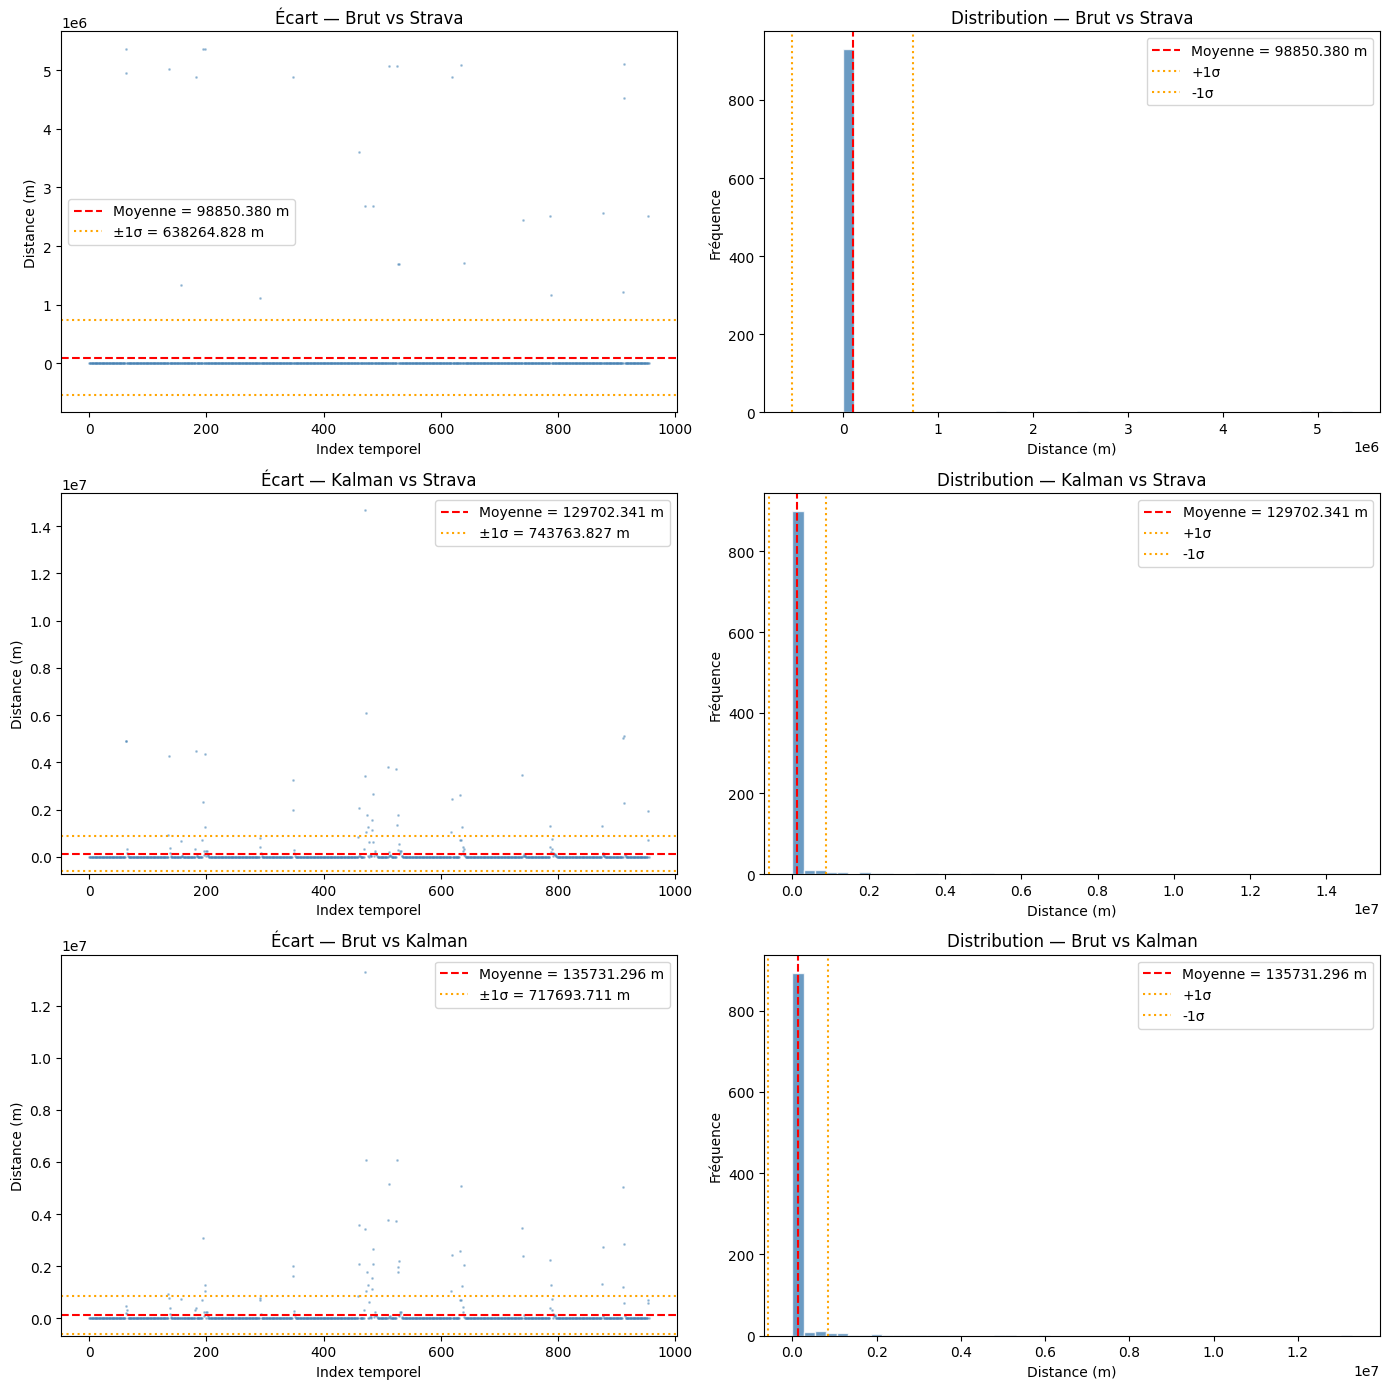

In [102]:
import matplotlib.pyplot as plt
import numpy as np

distances = {
    'Brut vs Strava':   df_merged['dist_brut_strava'],
    'Kalman vs Strava': df_merged['dist_kalman_strava'],
    'Brut vs Kalman':   df_merged['dist_brut_kalman'],
}

fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for i, (label, serie) in enumerate(distances.items()):
    moyenne    = serie.mean()
    ecart_type = serie.std()
    mediane    = serie.median()

    print(f"=== {label} ===")
    print(f"  Moyenne    : {moyenne:.4f} m")
    print(f"  Écart-type : {ecart_type:.4f} m")
    print(f"  Médiane    : {mediane:.4f} m")
    print(f"  Min        : {serie.min():.4f} m")
    print(f"  Max        : {serie.max():.4f} m\n")

    # Nuage de points
    axes[i, 0].scatter(range(len(serie)), serie, s=1, alpha=0.4, color='steelblue')
    axes[i, 0].axhline(moyenne,               color='red',    linestyle='--', label=f'Moyenne = {moyenne:.3f} m')
    axes[i, 0].axhline(moyenne + ecart_type,  color='orange', linestyle=':',  label=f'±1σ = {ecart_type:.3f} m')
    axes[i, 0].axhline(moyenne - ecart_type,  color='orange', linestyle=':')
    axes[i, 0].set_xlabel("Index temporel")
    axes[i, 0].set_ylabel("Distance (m)")
    axes[i, 0].set_title(f"Écart — {label}")
    axes[i, 0].legend()

    # Histogramme
    axes[i, 1].hist(serie, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
    axes[i, 1].axvline(moyenne,              color='red',    linestyle='--', label=f'Moyenne = {moyenne:.3f} m')
    axes[i, 1].axvline(moyenne + ecart_type, color='orange', linestyle=':',  label='+1σ')
    axes[i, 1].axvline(moyenne - ecart_type, color='orange', linestyle=':',  label='-1σ')
    axes[i, 1].set_xlabel("Distance (m)")
    axes[i, 1].set_ylabel("Fréquence")
    axes[i, 1].set_title(f"Distribution — {label}")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()